**Data Loading and Inspection**

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Objective:** Use simple, reusable Python functions to load real IMU and model-derived strain data, inspect arrays and participant labels, then visualise representative signals. No training is performed.

**Dataset:** Authors' public BoneNet walking/running derivative, not the entire Essex Figshare archive. Subject-row matching and target units require further independent validation.

**01. Environment and imports**

The main functions live in .py files. This cell adds the local source folders to the Python path, so **no custom hmi package or editable installation is needed**. Install standard dependencies once from a terminal using: python -m pip install -r requirements.txt.

In [1]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / 'requirements.txt').is_file() or not (root / 'python_modules/core/data_loading.py').is_file():
    if root.parent == root:
        raise RuntimeError('Open this notebook from within human-movement-intelligence.')
    root = root.parent

sys.path.insert(0, str(root / 'python_modules'))
sys.path.insert(0, str(root / 'biomechanical_load_estimation' / 'code' / 'src'))

import matplotlib.pyplot as plt
from IPython.display import display

from core.data_loading import load_data
from core.data_inspection import inspect_data, plot_signal
from bonenet_data import ensure_bonenet_files, load_bonenet_data

print('Project:', root)
print('Python:', sys.executable)
print('Data-loading functions: ready')

Project: D:\human-movement-intelligence
Python: c:\Users\Reza\AppData\Local\Programs\Python\Python314\python.exe
Data-loading functions: ready


**02. Prepare the data source**

ensure_bonenet_files() downloads Data.mat and labels.csv **once** from the authors' public repository, if missing. They are stored under data/raw/ and ignored by Git.

In [2]:
data_dir = root / 'data' / 'raw' / 'bonenet_reference'
ensure_bonenet_files(data_dir)
print('Source data folder:', data_dir)

Source data folder: D:\human-movement-intelligence\data\raw\bonenet_reference


**03. Read the source with a general reader**

load_data() understands CSV, Excel, text and standard MAT files. It does **not** assume that a particular variable is an IMU signal.

In [3]:
labels_table = load_data(data_dir / 'labels.csv')
source_mat = load_data(data_dir / 'Data.mat')
print('MAT variables:', [key for key in source_mat if not key.startswith('__')])
label_report = inspect_data(labels_table, name='BoneNet label table')
print('Distinct subject IDs:', labels_table['SubjID'].nunique())

MAT variables: ['inputs', 'outputs']

===== BoneNet label table =====
Rows: 444 | Columns: 3
Missing values: 0
Columns: SubjID, Task, TrialNum
SubjID    Task  TrialNum
subj04 Running         1
subj04 Running         2
subj04 Running         3
subj04 Running         1
subj04 Running         2
Distinct subject IDs: 37


**04. Convert the source layout into numeric arrays**

The **BoneNet-specific** adapter assembles the x/y/z IMU channels and e1/e3 output arrays. This step is not part of the general file reader.

In [4]:
X, y, labels, channel_names, target_names = load_bonenet_data(data_dir)
input_report = inspect_data(X, name='IMU input: N x channels x time')
target_report = inspect_data(y, name='FE target: N x time x outputs')
print('Example channels:', channel_names[:6])
print('Target channels:', target_names)

IMU X: (444, 42, 101) | FE targets y: (444, 101, 2)
Subject identifiers in labels: 37

===== IMU input: N x channels x time =====
Shape: (444, 42, 101) | Data type: float64
NaN/Inf count: 0
Preview of first observation:
[[ 1.46123540e+02  1.23889868e+02 ...  3.68875008e+01 -9.39954000e+00]
 [ 5.55440000e-01 -6.54764800e-01 ...  3.53090264e+01  3.71616800e+01]
 ...
 [-7.89387000e+00 -7.99240480e+00 ...  1.62754360e+00  1.96218000e+00]
 [ 2.35280000e-01  1.39951200e-01 ...  3.00432800e-01  2.77470000e-01]]

===== FE target: N x time x outputs =====
Shape: (444, 101, 2) | Data type: float64
NaN/Inf count: 0
Preview of first observation:
[[ 2554.  -6313. ]
 [ 2447.2 -6048.1]
 ...
 [  265.9  -578.5]
 [  169.   -328. ]]
Example channels: ['x.right_foot_acc', 'x.left_foot_acc', 'x.right_shank_acc', 'x.left_shank_acc', 'x.right_thigh_acc', 'x.left_thigh_acc']
Target channels: ['e1', 'e3']


**5. Plot actual signal values**

These are examples from the source arrays, not simulated figures. The original physical units and the correctness of row-order label associations have **not** been independently established.

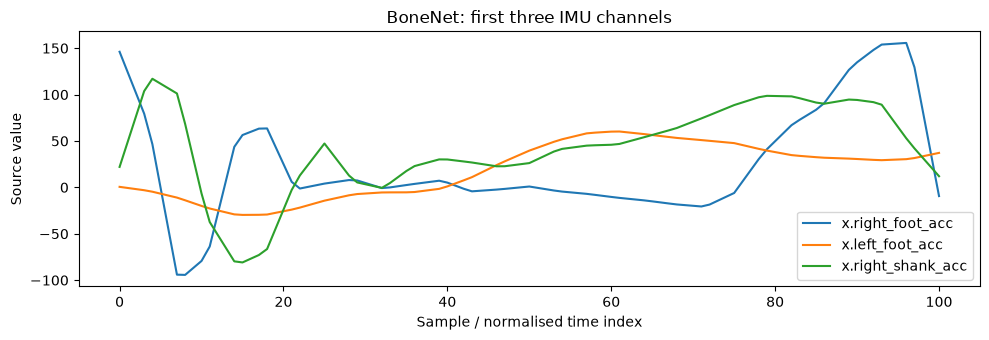

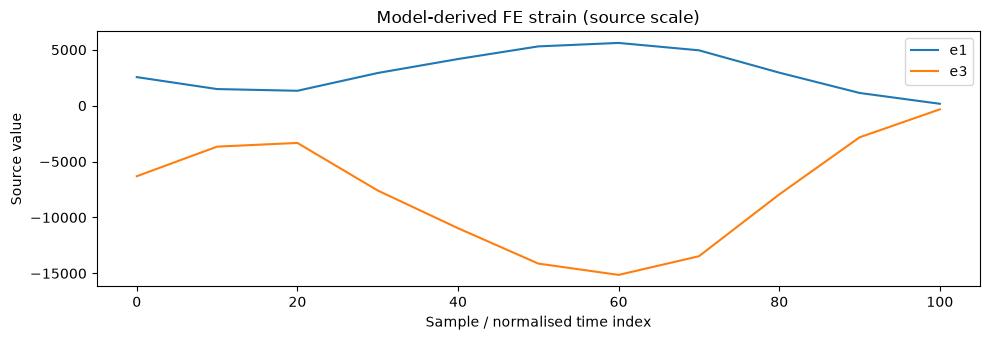

In [5]:
example_record = 0
fig1 = plot_signal(X[example_record, :3, :], title='BoneNet: first three IMU channels',
                   channel_names=channel_names[:3])
plt.show()

fig2 = plot_signal(y[example_record].T, title='Model-derived FE strain (source scale)',
                   channel_names=target_names)
plt.show()

**6. Quality gate and interpretation**

This notebook demonstrates loading, profiling and plotting, **not** data leakage control, validated biomechanical ground truth or model evaluation.

In [6]:
assert X.shape[0] == y.shape[0] == len(labels)
assert X.ndim == 3 and y.ndim == 3
print('Structural data loading: PASSED')
print('Independent subject-to-row alignment: NOT VERIFIED')
print('Model training performed: NO')

Structural data loading: PASSED
Independent subject-to-row alignment: NOT VERIFIED
Model training performed: NO
